In [1]:
import numpy as np
import pandas as pd
import math
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PowerTransformer, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import glob
from scipy.spatial import ConvexHull, Delaunay, cKDTree


FUNCTIONS

In [5]:
def import_2pcf(path):
    '''Import .dat files of theory_2pcf'''
    files_names = sorted(glob.glob(f"{path}/id*2pcf.dat"))
    files_full = [np.loadtxt(file) for file in files_names]
    files = []

    for i in range(len(files_full)):
        data = files_full[i]
        row = [row[1] for row in data]
        files.append(row)

    return files


def pca_fn(data, scaler, pca):
    '''Apply PCA on a set of points, return principal_components,expained_variance_ratio'''
    # Standardisation
    scaled_full = scaler.fit_transform(data)
    
    # PCA
    principal_components = pca.fit_transform(scaled_full)

    return principal_components, pca.explained_variance_ratio_


def project_new_data(new_data, scaler, pca):
    '''Project new dataset on chosen PCA'''
    # Standardisation
    scaled_new_data = scaler.transform(new_data)
    
    # Projection of new data on pre-existing principal components
    new_principal_components = pca.transform(scaled_new_data)
    
    return new_principal_components


def camb_crash_plot(lhs_camb_path, pca, color='red', s=25, label='CAMB crashes', marker='x'):
    '''Plot CAMB crashes'''
    params = pd.read_csv(lhs_camb_path)
    cambres = params['camb_res']
    params_crash = params[params['camb_res']==0]
    indices = params_crash.index

    plt.scatter(pca[indices,0],pca[indices,1],s=s, color=color, label=label, marker=marker)


def pca_without_camb_crash(lhs_camb_path,pca):
    '''Returns PCA projection without CAMB CRASHES'''
    params = pd.read_csv(lhs_camb_path)
    cambres = params['camb_res']
    params_crash = params[params['camb_res']==0]

    indices_to_exclude = params_crash.iloc[:, 0].values
    mask = np.ones(pca.shape[0], dtype=bool)
    mask[indices_to_exclude] = False

    pca_without_camb = pca[mask]
    return pca_without_camb

def maximin_distance_2D(pca, n_points, original_pca, selected_points=[]):
    """Take n_points among points, maximizing distance. Returns indices in original_pca
    pca = dataset to get points in (ex : pca without camb)
    original_pca = original points (to keep indices)"""
    pc1 = original_pca[:,0]
    pc2 = original_pca[:,1]
    orignal_pca = list(zip(pc1,pc2))
    selected_indices = []

    points = list(zip(pca[:,0],pca[:,1]))
    new_points = [] # New points exclusively from big LHS
    
    if len(selected_points)==0:
        further_indice = np.argmax(pca[:,0])
        further_indice1 = np.where(original_pca==points[further_indice])[0][0]
        further_point = original_pca[further_indice1]
        selected_points.append(list(further_point)) 
        new_points.append(further_point)
        selected_indices.append(further_indice1)

    if isinstance(selected_points, np.ndarray):
        selected_points = list(zip(selected_points[:,0],selected_points[:,1]))

    while len(selected_points) < n_points:
        max_min_distance = -1
        next_point = None
        
        for point in points:
            if point not in selected_points:
                min_distance = math.inf
                
                for selected_point in selected_points:
                    distance = math.sqrt((point[0] - selected_point[0])**2 + (point[1] - selected_point[1])**2)
                    if distance < min_distance:
                        min_distance = distance
                
                if min_distance > max_min_distance:
                    max_min_distance = min_distance
                    next_point = point
                    indice = np.where((pc1 == point[0]) & (pc2 == point[1]))[0][0]
        
        selected_points.append(next_point) # Contains 25 original + new points from big LHS
        new_points.append(next_point) # Contains new points from big LHS (for indices)
        selected_indices.append(indice)

    np.array(selected_points)
    np.array(new_points)
        
    return selected_indices

def opt_kmeans(data, n_points, random_state=None):
    """Apply kmeans method to get n_points from data"""
    kmeans = KMeans(n_clusters=n_points,random_state=random_state)
    kmeans.fit_transform(data)
    cluster_centers = kmeans.cluster_centers_

    selected_indices = []
    for center in cluster_centers:
        # Calculate distances
        distances = np.linalg.norm(data - center, axis=1)
        # Find closest point
        closest_index = np.argmin(distances)
        selected_indices.append(closest_index)

    return selected_indices

def plot_projections(pca_big,pca_opt,title = 'First Two PC',label='Selected points'):
    """Plot PCA and projections of selected points on two principal components"""
    pc1_big = pca_big[:,0]
    pc2_big = pca_big[:,1]

    pc1_opt = pca_opt[:,0]
    pc2_opt = pca_opt[:,1]

    fig = plt.figure(figsize=(10, 8))

    # Subplots dimensions
    grid = plt.GridSpec(4, 4, hspace=0.2, wspace=0.2)

    # Plot principal
    main_ax = fig.add_subplot(grid[:-1, 1:])

    # Add subplots for projection on PC1 and PC2
    y_hist = fig.add_subplot(grid[:-1, 0], xticklabels=[], sharey=main_ax)
    x_hist = fig.add_subplot(grid[-1, 1:], yticklabels=[], sharex=main_ax)

    # Scatter plot principal
    scatter = main_ax.scatter(pc1_big, pc2_big, s=2, alpha=1, color='skyblue', label='LHS2000 CAMB : success')
    main_ax.scatter(pc1_opt, pc2_opt, color='red', s=5, label=label)

    # Projection on axes
    x_hist.scatter(pc1_opt, [0] * len(pc1_opt), color='red', s=5, alpha=0.5)
    y_hist.scatter([0] * len(pc2_opt), pc2_opt, color='red', s=5, alpha=0.5)
    
    # Limits and labels
    main_ax.set_xlabel(f'First Principal Component : {round(100 * fc1, 2)}%')
    main_ax.set_ylabel(f'Second Principal Component : {round(100 * fc2, 2)}%')
    x_hist.set_xlim(main_ax.get_xlim())
    y_hist.set_ylim(main_ax.get_ylim())
    x_hist.xaxis.set_label_position('bottom')
    x_hist.set_xlabel(f'First Principal Component : {round(100 * fc1, 2)}%')

    y_hist.yaxis.set_label_position('left')
    y_hist.set_ylabel(f'Second Principal Component : {round(100 * fc2, 2)}%')

    main_ax.legend()
    main_ax.set_title(title)

    # Mask on subplots
    x_hist.yaxis.set_major_locator(plt.NullLocator())
    y_hist.xaxis.set_major_locator(plt.NullLocator())

    # Display plot
    plt.tight_layout()
    plt.show()

def convex_plot(principal_components,color='red'):
    '''Plot convex full for one PCA'''
    hull = ConvexHull(principal_components)
    for simplex in hull.simplices:
        plt.plot(principal_components[simplex,0],principal_components[simplex,1],color=color,linewidth=0.8)

def find_closest_points(opt_points, pca_points):
    """Take optimized points and find the indices (or closest indices) from original PCA, useful to come back to original cosmologies"""
    closest_indices = []
    for opt_point in opt_points:
        # Calculate distances from the current OPT point to all PCA points
        distances = np.linalg.norm(pca_points - opt_point, axis=1)
        # Find the index of the closest PCA point
        closest_index = np.argmin(distances)
        closest_indices.append(closest_index)

    return closest_indices

Import files and apply PCA

In [3]:
# IMPORT FILES
l2000_files = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0')
l25_0 = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_25_0')

# csv of parameters with "camb_res" column
param_path_l2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"

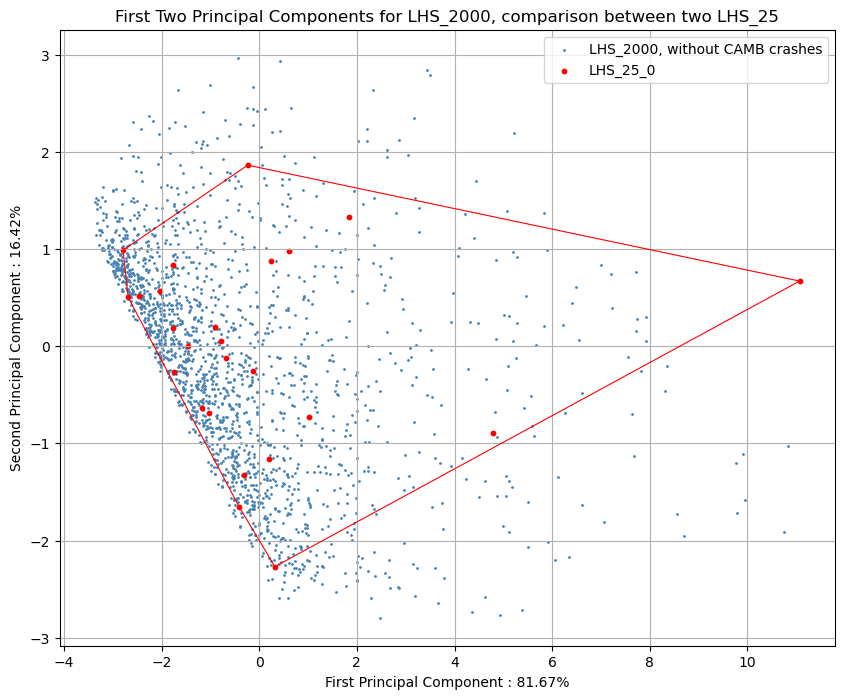

In [4]:
#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc2000_camb = pca_without_camb_crash(param_path_l2000,pc2000)
pc25_0 = project_new_data(l25_0, scaler, pca)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]
    
#######################################################################
# PLOTS 
######################################################################

#PLOTS button
convexhull = 1

plt.figure(figsize=(10, 8))
#plt.scatter(pc2000[:, 0], pc2000[:, 1],s=1,alpha=1,color='orangered',label='LHS_2000')
plt.scatter(pc2000_camb[:, 0], pc2000_camb[:, 1],s=1,alpha=1,color='steelblue',label='LHS_2000, without CAMB crashes')
plt.scatter(pc25_0[:, 0], pc25_0[:, 1],s=10,alpha=1,color='red',label='LHS_25_0')
if convexhull :
    #convex_plot(pc2000_restricted, 'firebrick')
    convex_plot(pc25_0, 'red')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components for LHS_2000, comparison between two LHS_25')
plt.legend()
plt.grid()
plt.show()

Create 1st opt dataset : maximizing distance

In [ ]:
opt_indices_rest_2D = maximin_distance_2D(pc2000_camb, 25, pc2000)
opt_pc25_rest = pc2000[opt_indices_rest_2D]

plot_projections(pc2000_camb,opt_pc25_rest,title = 'First Two PC',label='Selected points')

In [ ]:
# Create and export csv
params_list = ['Om','S8','h','w0','sig8','Oc','zmax','lmax','final_As','final_sig8']
param_path_2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"
params_2000 = pd.read_csv(param_path_2000)
params_2000 = params_2000[params_list]
l25_1st = params_2000.iloc[opt_indices_rest_2D, :]

l25_1st = l25_1st.reset_index(drop=True)

#l25_1st.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/lhs_25_1st.csv')

Create 2nd dataset : k-means

In [24]:
l2000_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path_l2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"
params_2000 = pd.read_csv(param_path_l2000)

l2000_files = import_2pcf(l2000_path)

print("Shape l2000 : ",np.shape(l2000_files))

# PARAMETERS WITH CAMB CRASHES


#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc2000_camb = pca_without_camb_crash(param_path_l2000,pc2000)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]

Shape l2000 :  (2000, 10)


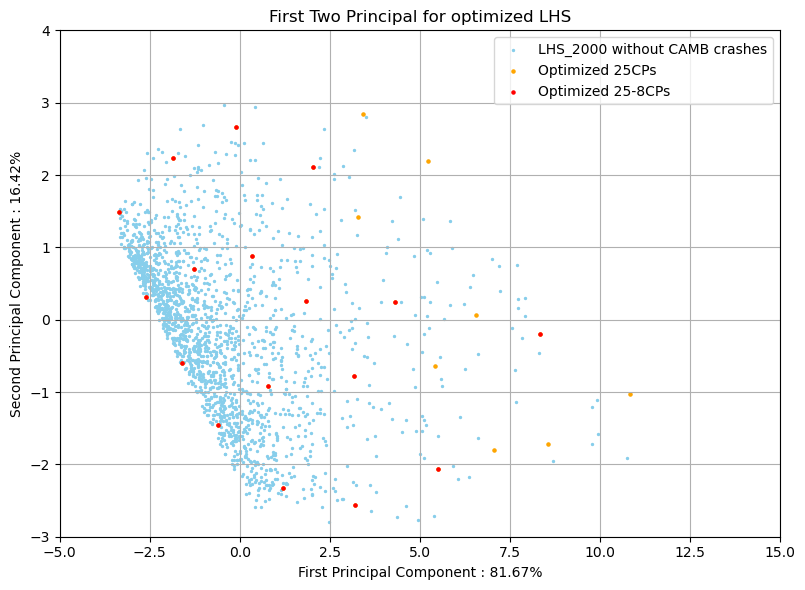

In [25]:
# 
opt_indices_25_2D = maximin_distance_2D(pc2000_camb, 25, pc2000)
opt_pc25 = pc2000[opt_indices_25_2D]

dim_opt25 = opt_pc25[[1,2,5,6,7,9,10,11,12,14,15,16,17,18,20,22,24]]
new_points_zone = pc2000[np.where((pc2000[:,0]+pc2000[:,1])<0)]
new_8points = opt_kmeans(new_points_zone,8,40)
final_25 = np.concatenate([new_points_zone[new_8points],dim_opt25])
                               
#0,3,4,8,13,18,21
convexhull=0
fig= plt.figure(figsize=(8, 6))
plt.scatter(pc2000_camb[:,0],pc2000_camb[:,1], s=2, alpha=1,color='skyblue', label='LHS_2000 without CAMB crashes')
#plt.scatter(new_points_zone[:,0],new_points_zone[:,1], s=2, alpha=1,color='orange', label='zone for new points (y+x<0)')
plt.scatter(opt_pc25[:,0],opt_pc25[:,1], s=5, alpha=1,color='orange', label='Optimized 25CPs')
plt.scatter(dim_opt25[:,0],dim_opt25[:,1], s=5, alpha=1,color='red', label='Optimized 25-8CPs')
#plt.scatter(pc2000[opt_indices_25_2D,0],pc2000[opt_indices_25_2D,1], color='red', s=5, label='Optimized 25CPs maximizing distance')
"""for x,y in enumerate(opt_pc25):
    plt.annotate(str(x),(y[0],y[1])) """
#plt.scatter(final_25[:,0],final_25[:,1], color='red', s=5, label='Optimized 25-8CPs maximizing distance')
#plt.scatter(new_points_zone[new_8points,0],new_points_zone[new_8points,1], color='green', s=5, label='New 8 points with K-means')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
if convexhull:
    convex_plot(opt_pc25, 'green')
plt.legend()
plt.title('First Two Principal for optimized LHS')
plt.tight_layout()
plt.xlim(-5,15)
plt.ylim(-3,4)
plt.grid()
plt.show()

/tmp/ipykernel_23301/210020757.py:173: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


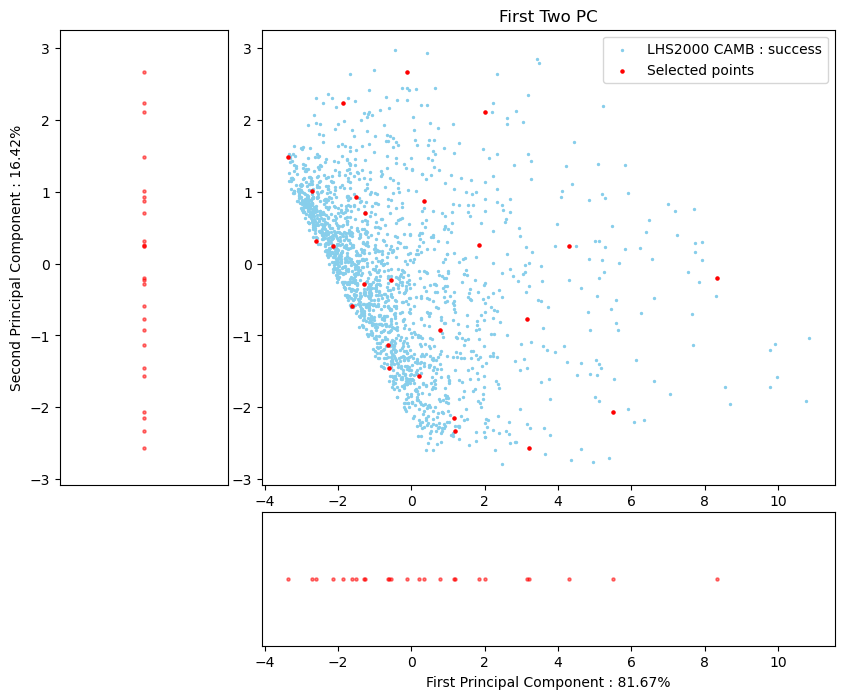

In [26]:
#Create and export csv
final_25_kmeans = find_closest_points(final_25,pc2000)
plot_projections(pc2000_camb,pc2000[final_25_kmeans],title = 'First Two PC',label='Selected points')

final_25kmeans_points = params_2000.iloc[final_25_kmeans,:]
final_25kmeans_points = final_25kmeans_points.reset_index(drop=True)

#final_25kmeans_points.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/25_kmeans.csv')

Create 3rd dataset : density groups

In [13]:
# IMPORT FILES
l2000_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'

l2000_files = import_2pcf(l2000_path)

print("Shape l2000 : ",np.shape(l2000_files))

# PARAMETERS WITH CAMB CRASHES
param_path_l2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"
params = pd.read_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv')
Om = params['Om']
S8 = params['S8']

#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc2000_camb = pca_without_camb_crash(param_path_l2000,pc2000)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]

Shape l2000 :  (2000, 10)


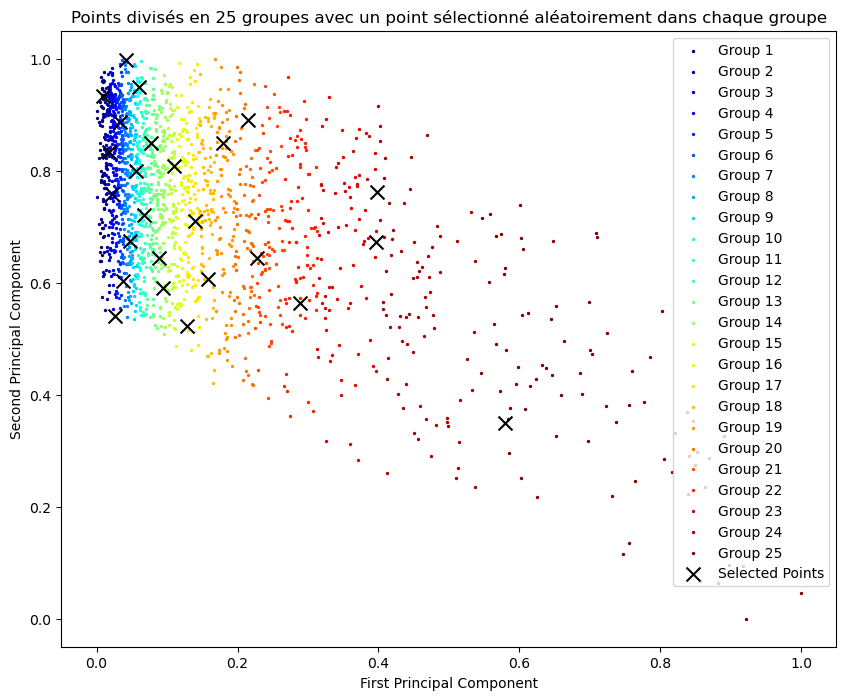

In [14]:
# Rotation of the dataset
def rotate_points(x, y, angle_degrees):
    angle_rad = np.deg2rad(angle_degrees)
    rotation_matrix = np.array([[np.cos(angle_rad), -np.sin(angle_rad)],
                                [np.sin(angle_rad), np.cos(angle_rad)]])
    rotated_points = np.dot(rotation_matrix, np.vstack([x, y]))
    return np.column_stack((rotated_points))

rotated = rotate_points(pc2000_camb[:, 0], pc2000_camb[:, 1], -45)

# Normalize 
scaler = MinMaxScaler()
data = scaler.fit_transform(rotated)

# Sort points on first principal component
sorted_indices = np.argsort(data[:, 0])
sorted_data = data[sorted_indices]

# Divide points in 25 groups
n_groups = 25
groups = np.array_split(sorted_data, n_groups)

# create list for points
selected_points = []

for i, group in enumerate(groups):
    min_dist = 1e-6 
    if len(selected_points)==0:
        np.random.seed(0)
        candidate_point = group[np.random.choice(group.shape[0])]
        selected_points.append(list(candidate_point))
    else :
        threshold = 0.05
        while min_dist<threshold:
            candidate_point = group[np.random.choice(group.shape[0])]
            distances = np.linalg.norm(np.array(selected_points) - np.array([candidate_point]*len(selected_points)), axis=1)
            min_dist = np.min(distances)
        selected_points.append(list(candidate_point))
        
selected_points=np.array(selected_points)
selected_indices = find_closest_points(selected_points,data)

plt.figure(figsize=(10, 8))
colors = plt.cm.jet(np.linspace(0, 1, n_groups))
for i, group in enumerate(groups):
    plt.scatter(group[:, 0], group[:, 1], color=colors[i], label=f'Group {i+1}',s=2)
plt.scatter(selected_points[:, 0], selected_points[:, 1], color='black', marker='x', s=100, label='Selected Points')
plt.title("Points divisés en 25 groupes avec un point sélectionné aléatoirement dans chaque groupe")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend()
plt.show()


/tmp/ipykernel_23301/210020757.py:173: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


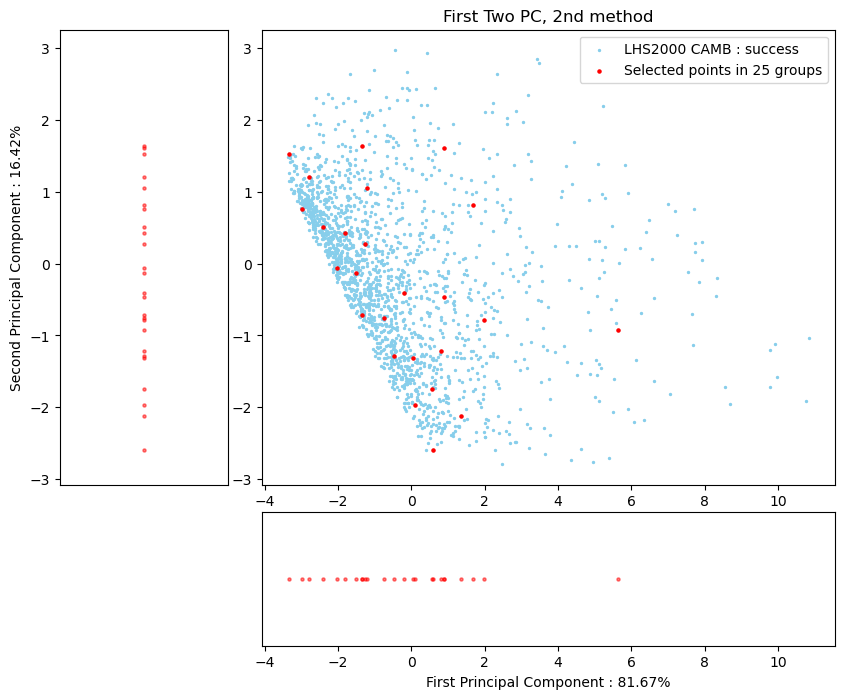

In [17]:
# Create and export csv
final_25groups_indices = find_closest_points(pc2000_camb[selected_indices],pc2000)
final_25groups_points = params.iloc[final_25groups_indices,:]
final_25groups_points = final_25groups_points.reset_index(drop=True)
#final_25groups_points.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/25_groups.csv')

plot_projections(pc2000_camb,pc2000_camb[selected_indices],title = 'First Two PC, 2nd method',label='Selected points in 25 groups')

PLOT COLORMAPS

Shape l2000 :  (2000, 10)


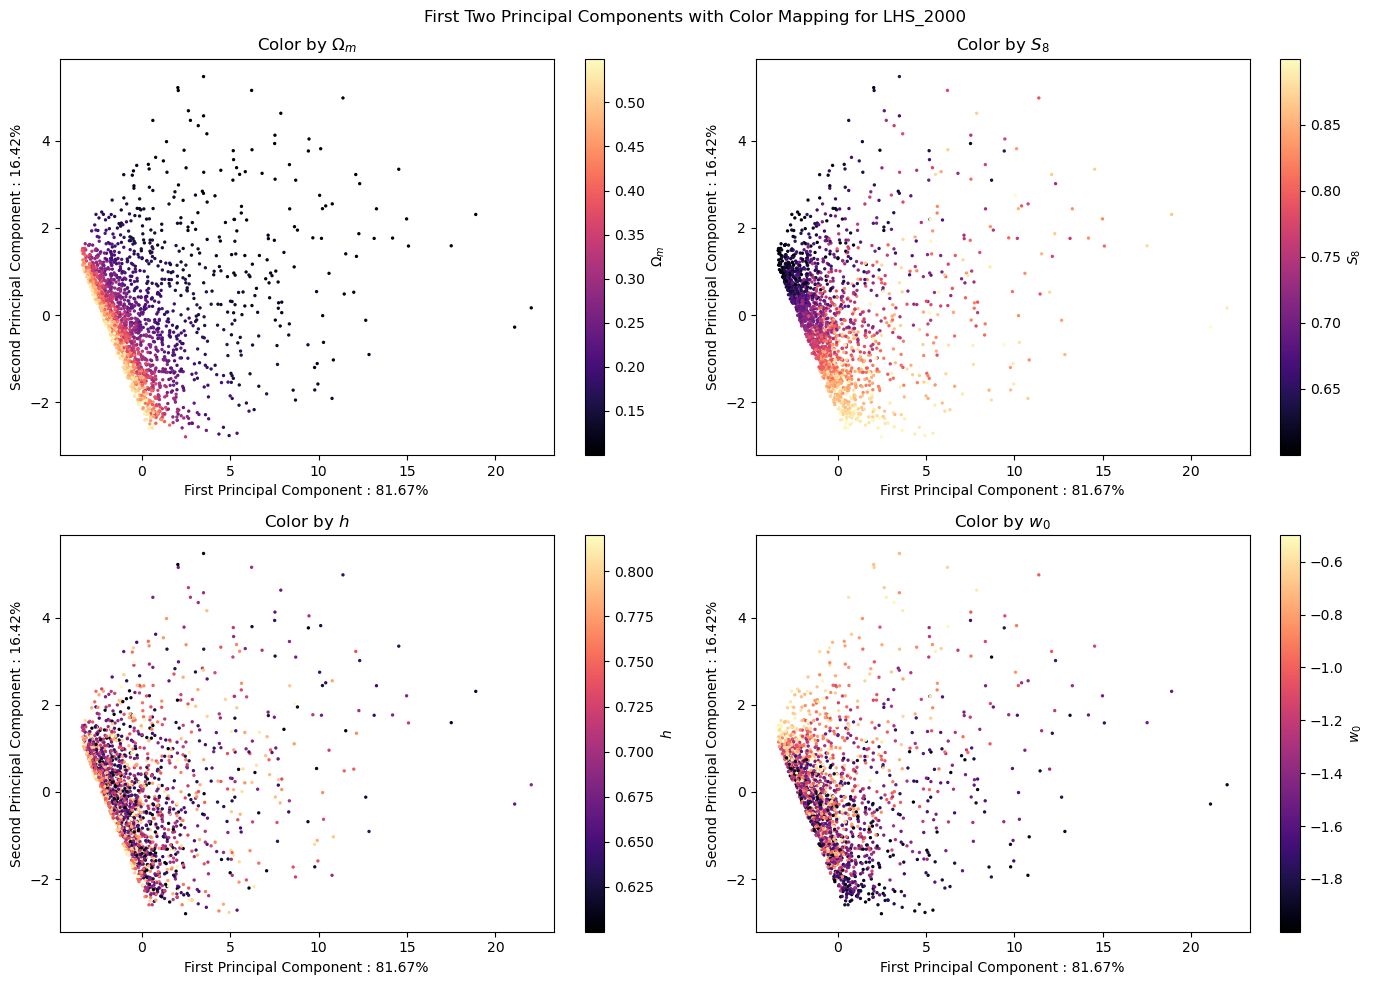

In [7]:
# Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$S_8$','$h$','$w_0$']
Om = params['Om']
S8 = params['S8']
h = params['h']
w0 = params['w0']
As = params['final_As']
params_values = [Om,S8,h,w0]

l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape l2000 : ",np.shape(l2000_files))

########################################################################
# PCA
scaler = StandardScaler()
scaled = scaler.fit_transform(l2000_files)

pca = PCA(n_components=4)
principal_components = pca.fit_transform(scaled)

########################################################################
# Explained variance
explained_variance = pca.explained_variance_ratio_
fc1 = explained_variance[0]
fc2 = explained_variance[1]
plot_variance = 0

if plot_variance : 
# Plot explained variance ratio
   plt.figure(figsize=(10, 7))
   plt.bar(range(0, pca.n_components_), pca.explained_variance_ratio_, alpha=0.5, align='center')
   plt.plot(np.cumsum(explained_variance), marker='o')
   plt.ylabel('Variance proportion')
   plt.xlabel('Principal components')
   plt.title('Variance explained by each component')
   plt.grid()
   plt.show()
   print(pca.explained_variance_ratio_)


#####################################################################
# PLOTS

# Create subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plot each subplot
for i, ax in enumerate(axs.flat):
    scatter = ax.scatter(principal_components[:, 0], principal_components[:, 1], 
                         c=params_values[i], s=2, alpha=1, cmap='magma')
    ax.set_xlabel(f'First Principal Component : {round(100*fc1,2)}%')
    ax.set_ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
    ax.set_title(f'Color by {params_list[i]}')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label(params_list[i])
    #plt.vlines(x = x_max, ymin = -3 ,ymax = y_max, color = 'b')
    #plt.hlines(y = y_max, xmin = -5 ,xmax = x_max, color = 'b')

plt.suptitle('First Two Principal Components with Color Mapping for LHS_2000')
plt.tight_layout()
plt.show()